In [75]:
pip install gspread pandas

In [76]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Important: Share Your Google Sheet

For `gspread` to access your Google Sheet, you need to share it. Here's how:

1.  **Open your Google Sheet.**
2.  Click the "Share" button (usually in the top right corner).
3.  Under "Get link," change the access to "Anyone with the link" and set the role to "Viewer" or "Editor" depending on your needs.
4.  Copy the URL of your Google Sheet. You will need this URL in the next step.

In [77]:
import gspread
import pandas as pd
from google.colab import auth
import numpy as np
import google.auth
import matplotlib.pyplot as plt

# Authenticate with Google Drive
auth.authenticate_user()

# Get default credentials and initialize gspread client
creds, _ = google.auth.default()
gc = gspread.authorize(creds)

# Replace 'YOUR_GOOGLE_SHEET_URL_HERE' with the actual URL of your Google Sheet
sheet_url = 'https://docs.google.com/spreadsheets/d/1LhdKb7kKxQaA-C0TI73SYEn2BYztbQz5L4cTzEFIaJs/edit?usp=sharing'

# Open the worksheet by its URL
try:
    worksheet = gc.open_by_url(sheet_url).sheet1  # .sheet1 refers to the first worksheet in the spreadsheet
    data = worksheet.get_all_values()
    df = pd.DataFrame(data[1:], columns=data[0]) # First row as headers, rest as data
    print("Successfully loaded Google Sheet into DataFrame!")
    display(df.head())
except gspread.exceptions.SpreadsheetNotFound:
    print(f"Error: Spreadsheet not found at URL: {sheet_url}. Please ensure the URL is correct and the sheet is shared.")
except gspread.exceptions.NoValidUrlKeyFound:
    print(f"Error: Invalid URL key found for: {sheet_url}. Please check the URL format.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Successfully loaded Google Sheet into DataFrame!


,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.24,0.17,16.12,0,Red,M
1,3042,0.05,25.42.00,16.6,0,Red,M
2,2600,0.03,1.42,18.7,0,Red,M
3,2800,0.02,0.16,17.05,0,Red,M
4,1939,2.18,1.43,20.06,0,Red,M


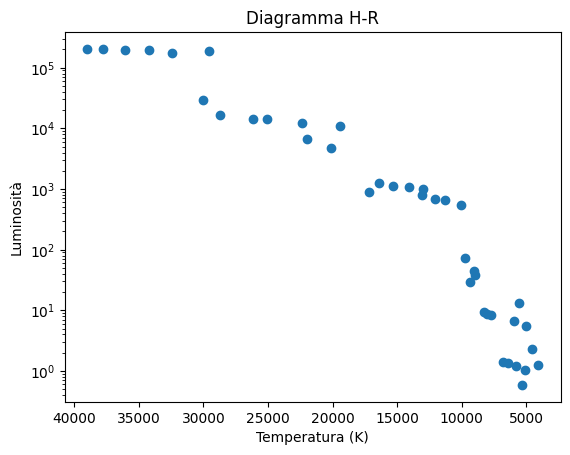

In [78]:
mskd_df = df[df['Star type'] == '3'].copy()

# conversione a numerico
mskd_df["Temperature (K)"] = pd.to_numeric(mskd_df["Temperature (K)"])
mskd_df["Luminosity(L/Lo)"] = pd.to_numeric(mskd_df["Luminosity(L/Lo)"])


# plot
plt.scatter(mskd_df["Temperature (K)"], mskd_df["Luminosity(L/Lo)"])

plt.yscale("log")
plt.gca().invert_xaxis()

plt.xlabel("Temperatura (K)")
plt.ylabel("Luminosità")
plt.title("Diagramma H-R")

plt.show()


LINEARE
train: 0.15725180763708868
test : 0.12943376041337817

POLINOMIALE
train: 0.08693286014193152
test : 0.4719191440911705


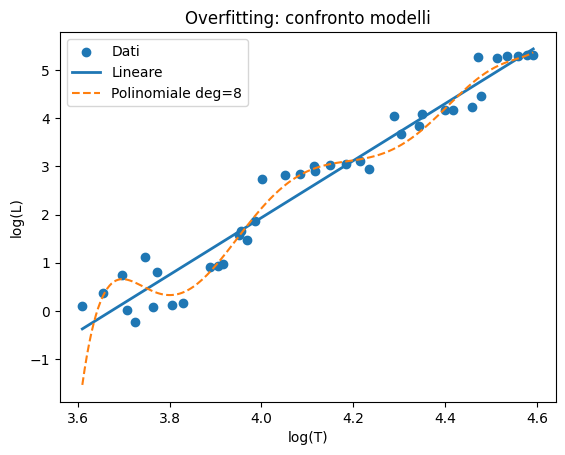

In [79]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

logT = np.log10(mskd_df["Temperature (K)"].values)
logL = np.log10(mskd_df["Luminosity(L/Lo)"].values)

X = logT.reshape(-1, 1)
y = logL

# =========================
# SPLIT
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# =========================
# MODELLI
# =========================
# semplice
model_lin = LinearRegression().fit(X_train, y_train)

# overfitting (molto complesso)
model_poly = make_pipeline(PolynomialFeatures(8), LinearRegression())
model_poly.fit(X_train, y_train)

# =========================
# ERRORI
# =========================
def mse(m, X, y):
    return mean_squared_error(y, m.predict(X))

print("LINEARE")
print("train:", mse(model_lin, X_train, y_train))
print("test :", mse(model_lin, X_test, y_test))

print("\nPOLINOMIALE")
print("train:", mse(model_poly, X_train, y_train))
print("test :", mse(model_poly, X_test, y_test))

# =========================
# PLOT
# =========================
plt.figure()

# dati veri
plt.scatter(X, y, label="Dati")

# asse per curve
x_line = np.linspace(X.min(), X.max(), 200).reshape(-1,1)

# linea semplice
plt.plot(x_line, model_lin.predict(x_line), label="Lineare", linewidth=2)

# curva overfit
plt.plot(x_line, model_poly.predict(x_line), label="Polinomiale deg=8", linestyle="--")

plt.xlabel("log(T)")
plt.ylabel("log(L)")
plt.title("Overfitting: confronto modelli")
plt.legend()

plt.show()